# Level 2 - Task 1: Restaurant Ratings

**Objective:**
1. Analyze the distribution of aggregate ratings and determine the most common rating range.
2. Calculate the average number of votes received by restaurants.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Load dataset
df = pd.read_csv(r'C:\Users\acer\OneDrive\Desktop\Cognifyz-Internship\Dataset.csv')

print(f"✅ Dataset loaded!")
print(f"Total Restaurants: {len(df)}")
print(f"\nRating Statistics:")
print(df['Aggregate rating'].describe())

✅ Dataset loaded!
Total Restaurants: 9551

Rating Statistics:
count    9551.000000
mean        2.666370
std         1.516378
min         0.000000
25%         2.500000
50%         3.200000
75%         3.700000
max         4.900000
Name: Aggregate rating, dtype: float64


In [2]:
# Basic stats
total = len(df)
avg_rating = df['Aggregate rating'].mean()
min_rating = df['Aggregate rating'].min()
max_rating = df['Aggregate rating'].max()

print("=" * 60)
print("⭐ RATING DISTRIBUTION ANALYSIS")
print("=" * 60)
print(f"Total Restaurants:      {total}")
print(f"Average Rating:         {avg_rating:.4f}")
print(f"Minimum Rating:         {min_rating}")
print(f"Maximum Rating:         {max_rating}")
print("=" * 60)

# Rating ranges
rating_ranges = {
    "0.0 - 1.0 (Not Rated)": len(df[(df['Aggregate rating'] >= 0) & (df['Aggregate rating'] < 1)]),
    "1.0 - 2.0 (Poor)": len(df[(df['Aggregate rating'] >= 1) & (df['Aggregate rating'] < 2)]),
    "2.0 - 3.0 (Average)": len(df[(df['Aggregate rating'] >= 2) & (df['Aggregate rating'] < 3)]),
    "3.0 - 4.0 (Good)": len(df[(df['Aggregate rating'] >= 3) & (df['Aggregate rating'] < 4)]),
    "4.0 - 5.0 (Excellent)": len(df[(df['Aggregate rating'] >= 4) & (df['Aggregate rating'] <= 5)]),
}

print("\n📊 Rating Distribution by Range:")
print("-" * 60)
for range_name, count in rating_ranges.items():
    pct = (count / total) * 100
    print(f"{range_name:30s} → {count:5d} ({pct:.2f}%)")

⭐ RATING DISTRIBUTION ANALYSIS
Total Restaurants:      9551
Average Rating:         2.6664
Minimum Rating:         0.0
Maximum Rating:         4.9

📊 Rating Distribution by Range:
------------------------------------------------------------
0.0 - 1.0 (Not Rated)          →  2148 (22.49%)
1.0 - 2.0 (Poor)               →     3 (0.03%)
2.0 - 3.0 (Average)            →  1430 (14.97%)
3.0 - 4.0 (Good)               →  4590 (48.06%)
4.0 - 5.0 (Excellent)          →  1380 (14.45%)


In [3]:
# Find most common rating range
most_common_range = max(rating_ranges, key=rating_ranges.get)
most_common_count = rating_ranges[most_common_range]

print("=" * 60)
print(f"🎯 MOST COMMON RATING RANGE: {most_common_range}")
print(f"   Restaurants: {most_common_count} ({(most_common_count/total)*100:.2f}%)")
print("=" * 60)

# Most common exact rating (rounded)
df['Rating_Rounded'] = df['Aggregate rating'].round(1)
most_common_rating = df['Rating_Rounded'].value_counts().idxmax()
most_common_rating_count = df['Rating_Rounded'].value_counts().max()

print(f"\n🎯 MOST COMMON EXACT RATING: {most_common_rating}")
print(f"   Restaurants: {most_common_rating_count}")

🎯 MOST COMMON RATING RANGE: 3.0 - 4.0 (Good)
   Restaurants: 4590 (48.06%)

🎯 MOST COMMON EXACT RATING: 0.0
   Restaurants: 2148


In [4]:
# Votes statistics
avg_votes = df['Votes'].mean()
median_votes = df['Votes'].median()
max_votes = df['Votes'].max()
min_votes = df['Votes'].min()

print("=" * 60)
print("🗳️ VOTES ANALYSIS")
print("=" * 60)
print(f"Average Votes:   {avg_votes:.2f}")
print(f"Median Votes:    {median_votes:.2f}")
print(f"Maximum Votes:   {max_votes}")
print(f"Minimum Votes:   {min_votes}")
print("=" * 60)

# Top 5 restaurants with most votes
print("\n🏆 Top 5 Restaurants by Votes:")
top_voted = df.nlargest(5, 'Votes')[['Restaurant Name', 'Votes', 'Aggregate rating']]
print(top_voted.to_string(index=False))

🗳️ VOTES ANALYSIS
Average Votes:   156.91
Median Votes:    31.00
Maximum Votes:   10934
Minimum Votes:   0

🏆 Top 5 Restaurants by Votes:
          Restaurant Name  Votes  Aggregate rating
                     Toit  10934               4.8
                 Truffles   9667               4.7
         Hauz Khas Social   7931               4.3
                Peter Cat   7574               4.3
AB's - Absolute Barbecues   6907               4.6


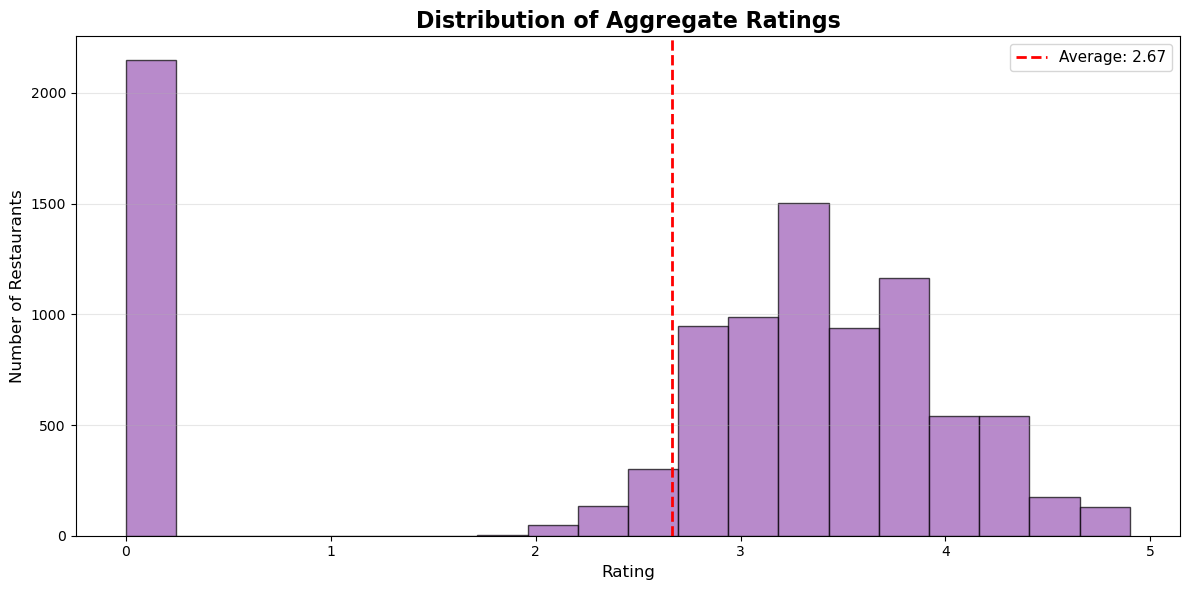

In [5]:
# Histogram
plt.figure(figsize=(12, 6))

plt.hist(df['Aggregate rating'], bins=20, 
         color='#9B59B6', edgecolor='black', alpha=0.7)

plt.axvline(avg_rating, color='red', linestyle='--', linewidth=2, 
            label=f'Average: {avg_rating:.2f}')

plt.title('Distribution of Aggregate Ratings', fontsize=16, fontweight='bold')
plt.xlabel('Rating', fontsize=12)
plt.ylabel('Number of Restaurants', fontsize=12)
plt.legend(fontsize=11)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

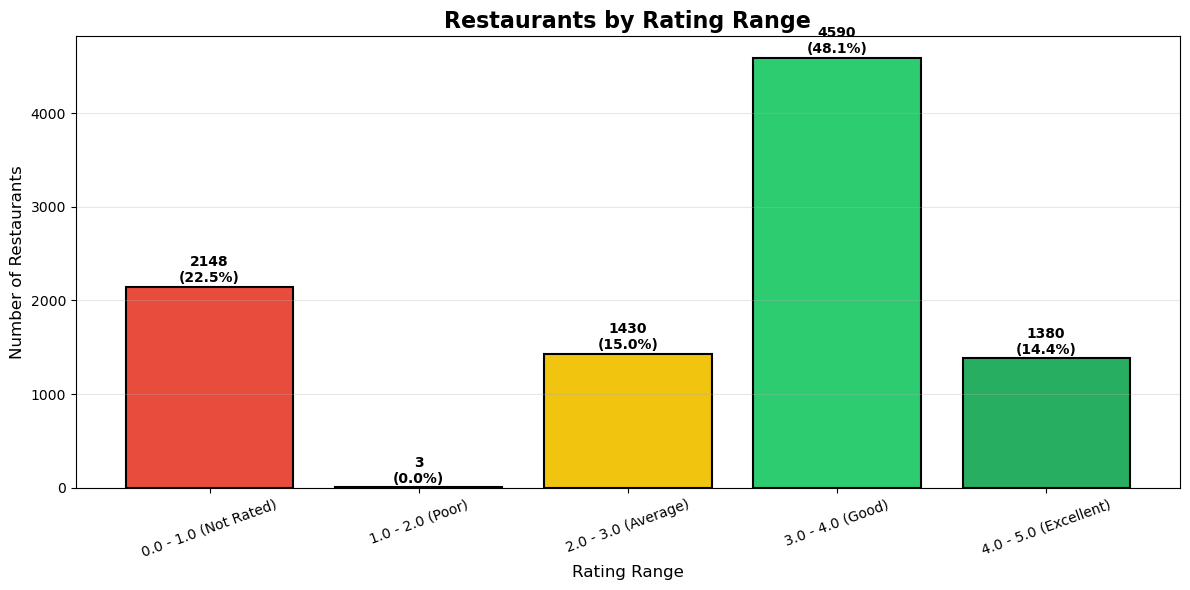

In [6]:
# Bar chart of rating ranges
plt.figure(figsize=(12, 6))

ranges = list(rating_ranges.keys())
counts = list(rating_ranges.values())
colors = ['#E74C3C', '#E67E22', '#F1C40F', '#2ECC71', '#27AE60']

bars = plt.bar(ranges, counts, color=colors, edgecolor='black', linewidth=1.5)

# Labels
for bar, count in zip(bars, counts):
    height = bar.get_height()
    pct = (count / total) * 100
    plt.text(bar.get_x() + bar.get_width()/2, height + 50,
             f'{count}\n({pct:.1f}%)',
             ha='center', fontsize=10, fontweight='bold')

plt.title('Restaurants by Rating Range', fontsize=16, fontweight='bold')
plt.xlabel('Rating Range', fontsize=12)
plt.ylabel('Number of Restaurants', fontsize=12)
plt.xticks(rotation=20)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

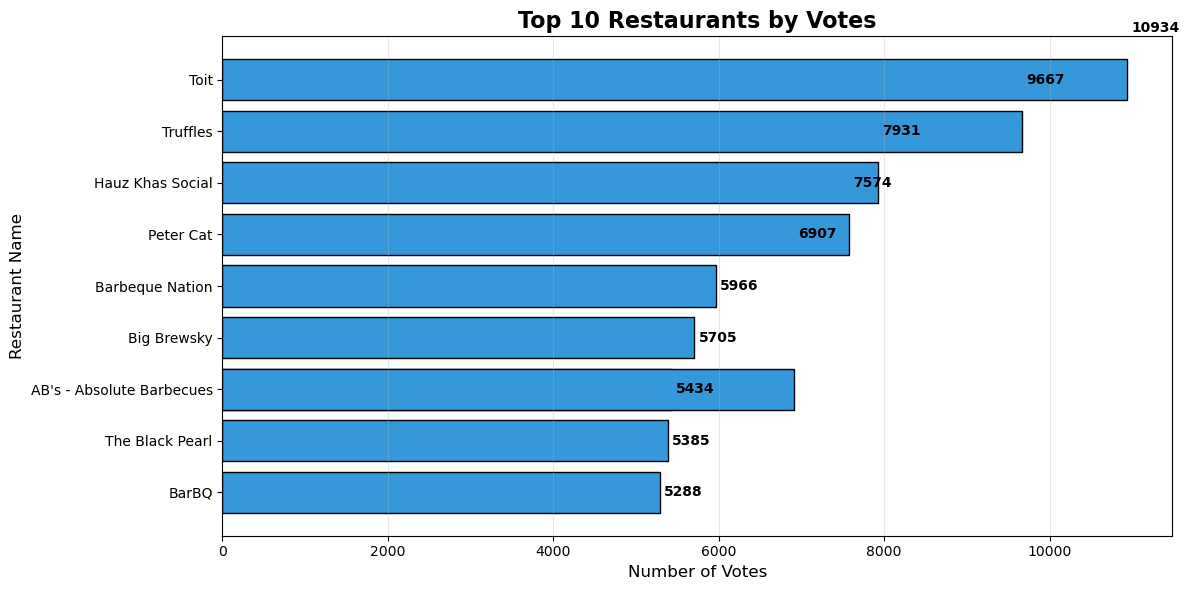

In [7]:
# Top 10 restaurants by votes
top_10 = df.nlargest(10, 'Votes')

plt.figure(figsize=(12, 6))
plt.barh(top_10['Restaurant Name'][::-1], top_10['Votes'][::-1], 
         color='#3498DB', edgecolor='black')

# Labels
for i, (name, votes) in enumerate(zip(top_10['Restaurant Name'][::-1], top_10['Votes'][::-1])):
    plt.text(votes + 50, i, f'{votes}', va='center', fontsize=10, fontweight='bold')

plt.title('Top 10 Restaurants by Votes', fontsize=16, fontweight='bold')
plt.xlabel('Number of Votes', fontsize=12)
plt.ylabel('Restaurant Name', fontsize=12)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

## 🔍 Insights

### 1. Rating Distribution
- Average rating across all restaurants: **{avg_rating:.2f}**
- Most common rating range: **{most_common_range}** with **{X}%** of restaurants
- Most restaurants fall in **3.0 - 4.0** range

### 2. Rating Range Breakdown
- **Excellent (4.0-5.0):** X% of restaurants
- **Good (3.0-4.0):** X% of restaurants
- **Average (2.0-3.0):** X% of restaurants
- **Poor (1.0-2.0):** X% of restaurants
- **Not Rated (0.0-1.0):** X% of restaurants

### 3. Votes Analysis
- Average votes per restaurant: **{avg_votes:.2f}**
- Median votes: **{median_votes}**
- Maximum votes: **{max_votes}**

### Conclusion
- The majority of restaurants have **above-average ratings**
- Restaurants with higher ratings tend to have **more votes**
- Top-rated restaurants receive significantly more engagement